# Custom loss functions in automl

This notebook walks through the custom-loss features of the `feature/custom-loss` branch. Your loss (`metric_optimise`) is now used in every stage of the learning, not only in hyperparameter optimisation:

| Stage | Before | Now |
|---|---|---|
| Hyperparameter optimisation | ✅ metric scored per fold | ✅ unchanged |
| Early stopping (`lightgbm`, `xgboost`, `catboost`) | library default metric (L2 / logloss) | your metric, on group aggregates if grouping |
| Training of boosted regression models | built-in loss | your `grad_hess`, or a known equivalent objective, else default + `LossFallbackWarning` |
| Stacking | `RidgeCV` (metric only picked `alpha`) | meta-learner whose weights directly optimise your loss (`stacking_meta_learner='loss'`) |
| Evaluation (`summary`) | `metric_assess` only, ungrouped | your loss always reported (last entry), all metrics grouped |
| Cross-validation with grouping | `KFold` (groups leak across folds) | `GroupKFold` by default |

Sections:
1. Setup and example data
2. How the loss is resolved per model
3. Group-level training up close (no hyperparameter optimisation)
4. Full run: grouped `r2_score`
5. Your own loss with `grad_hess` (asymmetric loss) and a gradient checker
6. A metric without gradient: the fallback warning
7. Multi-output: a loss on the ratio of two targets
8. Classification with a probability-based loss
9. Playground

## 1. Setup and example data

In [1]:
import os
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, log_loss, accuracy_score

from automl import AutomatedRegression, AutomatedClassification, CustomLoss, LossFallbackWarning

# -- results of each section are written to a fresh folder, such that re-running a section starts a new study
BASE_FOLDER = os.path.join(os.getcwd(), 'testdir', 'custom_loss')

def fresh_folder(name):
    folder = os.path.join(BASE_FOLDER, name)
    if os.path.exists(folder):
        shutil.rmtree(folder)
    return folder

def summary_frame(automl):
    """`summary` as a DataFrame: per model the mean (std) over the test folds, per metric"""
    names = [getattr(m, '__name__', f'metric_{i}') for i, m in enumerate(automl.metric_assess)]
    names += [f'LOSS: {automl.metric_optimise.name}']
    return pd.DataFrame({model: [f'{mean:.4f} ({std:.4f})' for mean, std in values]
                         for model, values in automl.summary.items()}, index=names).T

def safe_means(series_or_array, index):
    return pd.Series(np.ravel(series_or_array), index=index).groupby(level='safe').mean()

def test_scores(automl, metric=r2_score):
    """metric on the safe means of the ENTIRE test set, per fitted model and for the stacked model"""
    y_test = safe_means(automl.y_test, automl.X_test.index)
    models = dict(automl.estimators, stacked=automl._model_final)
    return pd.Series({name: metric(y_test, safe_means(model.predict(automl.X_test), automl.X_test.index))
                      for name, model in models.items()}, name=f'{metric.__name__} of safe means, entire test set').round(4)

/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The example data mimics `automl_test.ipynb`: observations indexed by `['safe', 'group', 'index']`. The crucial difference is that **the target is only meaningful on the scale of a safe**: the safe-mean of the target depends on the safe-mean of the features, while individual rows are dominated by noise. This is the situation where the observations have a higher resolution than the target, and a model should fit the large scale while being free on the small scale.

(5760, 10) | safes: 120


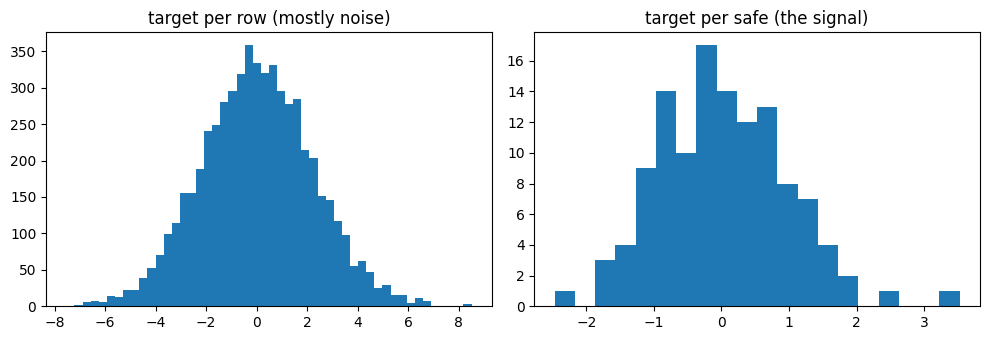

In [2]:
def make_safe_data(n_safes=120, rows_per_group=16, noise=2.0, seed=42):
    rng = np.random.default_rng(seed)
    rows = [(f'safe_{s:03d}', g, i) for s in range(n_safes) for g in [1, 2, 3]
            for i in rng.choice(101, size=rows_per_group, replace=False)]
    index = pd.MultiIndex.from_tuples(rows, names=['safe', 'group', 'index'])
    X = pd.DataFrame(rng.normal(size=(len(index), 10)), index=index, columns=[f'col_{i}' for i in range(10)])
    coef = rng.uniform(-1, 1, size=10)
    safe_signal = 4 * (X.groupby(level='safe').transform('mean') @ coef)
    y = (safe_signal + rng.normal(0, noise, size=len(index))).rename('target')
    return X, y

X, y = make_safe_data()
print(X.shape, '| safes:', X.index.get_level_values('safe').nunique())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y, bins=50); axes[0].set_title('target per row (mostly noise)')
axes[1].hist(y.groupby(level='safe').mean(), bins=20); axes[1].set_title('target per safe (the signal)')
plt.tight_layout()

## 2. How the loss is resolved per model

When an `AutomatedRegression` is created, the library decides per model how it trains on your loss:

1. a `grad_hess` you supplied in `CustomLoss` → **custom** objective
2. a known metric (`r2_score`, `mean_squared_error`, `root_mean_squared_error`, `explained_variance_score` → squared error; `mean_absolute_error`, `median_absolute_error` → absolute error) → **native** library objective, or a **custom** group-level objective when grouping
3. otherwise → model **default** objective, with a `LossFallbackWarning`

Non-boosted models (`bayesianridge`, `lassolars`, ...) always train on their built-in loss, but still use your loss for optimisation, stacking and evaluation. The resolution is visible in `automl._loss.objectives`:

In [3]:
def show_objectives(metric_optimise, **kwargs):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', LossFallbackWarning)
        reg = AutomatedRegression(y=y, X=X, metric_optimise=metric_optimise, write_folder=fresh_folder('resolve'),
                                  models_to_optimize=['lightgbm', 'xgboost', 'catboost', 'bayesianridge'], **kwargs)
    table = pd.DataFrame({name: {'kind': o.kind, 'native objective': o.native}
                          for name, o in reg._loss.objectives.items()}).T
    display(table)
    for w in caught:
        if issubclass(w.category, LossFallbackWarning):
            print('WARNING:', w.message, '\n')

print('r2_score, no grouping:'); show_objectives(r2_score)
print('r2_score, grouped per safe:'); show_objectives(r2_score, group_by_index_columns=['safe'], agg_func='mean')

r2_score, no grouping:


,kind,native objective
lightgbm,native,regression
xgboost,native,reg:squarederror
catboost,native,RMSE
bayesianridge,default,NaN


r2_score, grouped per safe:


,kind,native objective
lightgbm,custom,NaN
xgboost,custom,NaN
catboost,native,RMSE
bayesianridge,default,NaN


Note that `catboost` cannot train on group-level gradients: CatBoost evaluates custom objectives on arbitrary chunks of rows, which split groups. It falls back to the row-level native objective (and still uses the grouped loss for early stopping, stacking and evaluation).

## 3. Group-level training up close

Before running the full pipeline, here is the core mechanism in isolation, without hyperparameter optimisation. The same LightGBM model is trained (a) on the usual row-level squared error and (b) on the squared error of the **safe means**. The gradient of (b) is computed per safe and distributed to its rows via the chain rule, so the model is only constrained on the scale of the safes.

In [4]:
import lightgbm as lgb
from automl.loss import LossHandler, TargetCenterer
from automl.estimators import LossAwarePipeline, LossAwareTransformedTargetRegressor

safes = X.index.get_level_values('safe')
train, test = safes < 'safe_090', safes >= 'safe_090'

results = {}
for label, grouping in [('row-level objective', None), ('safe-level objective', ['safe'])]:
    handler = LossHandler(CustomLoss(r2_score), greater_is_better=True, group_by_index_columns=grouping, agg_func='mean')
    handler.resolve_objectives(['lightgbm'])
    model, _ = handler.configure_estimator(lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, verbosity=-1), 'lightgbm')
    pipeline = LossAwarePipeline([('model', LossAwareTransformedTargetRegressor(model, transformer=TargetCenterer()))])
    pipeline.fit(X[train], y[train].to_frame())
    prediction = pipeline.predict(X[test])
    results[label] = {
        'objective used': type(model.get_params()['objective']).__name__,
        'R2 per row': r2_score(y[test], prediction),
        'R2 of safe means': r2_score(safe_means(y[test], X[test].index), safe_means(prediction, X[test].index)),
    }
pd.DataFrame(results).T

/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/lightgbm/basic.py:374: UserWarning: Converting column-vector to 1d array
  _log_warning("Converting column-vector to 1d array")
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/lightgbm/basic.py:374: UserWarning: Converting column-vector to 1d array
  _log_warning("Converting column-vector to 1d array")


,objective used,R2 per row,R2 of safe means
row-level objective,str,-0.06236,0.110628
safe-level objective,GradHessObjective,-0.399772,0.268736


The safe-level objective improves the fit of the safe means, the quantity that matters here. Its row-level R² can be strongly negative: the model is unconstrained within a safe, so individual rows may deviate freely as long as the safe means fit. That is the intended trade-off when only the large scale is valid.

## 4. Full run: grouped `r2_score`

Now the full pipeline. With `group_by_index_columns=['safe']` and `agg_func='mean'`:
- cross-validation defaults to `GroupKFold` (no safe in both training and validation fold)
- `lightgbm` and `xgboost` train on the safe-level objective; `catboost` would fall back (see section 2)
- early stopping evaluates R² of safe means on the validation fold
- the stacking meta-learner chooses its weights to maximise R² of safe means on out-of-fold predictions
- the summary reports all metrics on safe means

In [5]:
regression = AutomatedRegression(
    y=y,
    X=X,
    metric_optimise=r2_score,
    optimisation_direction='maximize',
    group_by_index_columns=['safe'],
    agg_func='mean',
    models_to_optimize=['bayesianridge', 'lightgbm', 'xgboost'],
    n_trial=10,
    timeout_study=90,
    n_weak_models=2,
    boosted_early_stopping_rounds=20,
    transformer_kwargs={'skip': True},
    write_folder=fresh_folder('grouped_r2'),
    random_state=0,
)
print('cross-validation:', regression.cross_validation)
regression.apply()
summary_frame(regression)

cross-validation: GroupKFold(n_splits=5, random_state=0, shuffle=True)


[I 2026-10-29 13:10:08,462] A new study created in RDB with name: regression_bayesianridge
[I 2026-10-29 13:10:08,547] Trial 0 finished with value: -0.13884437689962006 and parameters: {'scaler': 'minmax', 'max_iter': 175, 'tol': 64.58941131020667, 'alpha_1': 0.00023761404778025518, 'alpha_2': 8.274276086161445, 'lambda_1': 43.313931464059515, 'lambda_2': 6.829913261377665e-05, 'transformers': None}. Best is trial 0 with value: -0.13884437689962006.
[I 2026-10-29 13:10:08,826] Trial 1 finished with value: -0.07130861412484682 and parameters: {'scaler': 'robust', 'max_iter': 37, 'tol': 8.712929979282778, 'alpha_1': 1.5928833561691773e-08, 'alpha_2': 2.1193293640885194, 'lambda_1': 0.6047383484167921, 'lambda_2': 5.013274471944554, 'transformers': None}. Best is trial 1 with value: -0.07130861412484682.
[I 2026-10-29 13:10:09,064] Trial 2 finished with value: -0.08755478848334589 and parameters: {'scaler': None, 'max_iter': 56, 'tol': 63.992102136353175, 'alpha_1': 2.7135190452611025e-07

,median_absolute_error,r2_score,LOSS: r2_score
bayesianridge_best,0.6566 (0.2693),-0.0344 (0.1589),-0.0344 (0.1589)
bayesianridge_4,0.6586 (0.2706),-0.0477 (0.1613),-0.0477 (0.1613)
bayesianridge_5,0.6586 (0.2706),-0.0478 (0.1613),-0.0478 (0.1613)
lightgbm_best,0.5190 (0.2799),0.0521 (0.2792),0.0521 (0.2792)
lightgbm_3,0.6098 (0.2645),-0.0657 (0.1907),-0.0657 (0.1907)
lightgbm_7,0.6059 (0.2547),-0.0557 (0.2098),-0.0557 (0.2098)
xgboost_best,0.2477 (0.1276),0.7462 (0.0739),0.7462 (0.0739)
xgboost_1,0.5561 (0.4144),-0.0290 (0.2401),-0.0290 (0.2401)
xgboost_6,0.5801 (0.4123),0.0157 (0.3771),0.0157 (0.3771)
stacked,0.1812 (0.0596),0.8112 (0.0696),0.8112 (0.0696)


**Reading the summary with grouped data:** `summary` reports the mean (std) over cross-validation folds *of the test set*. With grouping, each fold only holds a few safes (here ~24 test safes over 5 folds), so a statistic like R² computed on a handful of safe means per fold is very noisy and can be strongly negative. Scale-dependent metrics (MAE, the loss itself) are more robust per fold. Scoring on the entire test set at once gives a clearer picture:

In [6]:
test_scores(regression)

/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X 

bayesianridge_best    0.0630
bayesianridge_4       0.0505
bayesianridge_5       0.0505
lightgbm_best         0.2132
lightgbm_3            0.0513
lightgbm_7            0.0678
xgboost_best          0.7676
xgboost_1             0.0849
xgboost_6             0.1003
stacked               0.8282
Name: r2_score of safe means, entire test set, dtype: float64

In [7]:
# -- weights of the loss-optimising meta-learner (non-negative, per selected model) and its intercept
stacker = regression._model_final
print(pd.Series(stacker.coef_.ravel(), index=[name for name, _ in stacker.estimators]).round(3).to_string())
print('intercept:', np.round(stacker.intercept_, 3))

# -- the fitted boosted models indeed carry the group-level objective
lgbm = dict(regression.estimators)['lightgbm_best']['model']
print('\nlightgbm objective:', type(lgbm.regressor.get_params()['objective']).__name__)

bayesianridge_best    0.000
bayesianridge_4       0.000
bayesianridge_5       0.000
lightgbm_best         0.000
lightgbm_3            0.000
lightgbm_7            0.000
xgboost_best          1.529
xgboost_1             0.000
xgboost_6             0.082
intercept: [-0.008]

lightgbm objective: GradHessObjective


The weights need not sum to one: if the base models systematically under- or overestimate the variation between safes (e.g. due to regularisation), the meta-learner can rescale them, since that improves the loss on out-of-fold predictions.

## 5. Your own loss with `grad_hess`

To train boosted models on a loss for which no equivalent objective is known, supply its gradient and hessian. As an example, an **asymmetric squared error** where under-prediction costs `k` times more than over-prediction.

The conventions of `grad_hess(y_true, y_pred) -> (grad, hess)`:
- derivatives with respect to `y_pred`, of the loss to **minimise**, as numpy arrays of the same shape as `y_pred`
- derivatives of a **sum** of losses (the LightGBM/XGBoost convention), so no division by the number of samples
- with grouping, `y_true` and `y_pred` are already the group aggregates; the chain rule to rows is applied for you
- `hess` is the diagonal of the hessian and should be positive

A finite-difference checker helps to validate your derivatives before training:

In [8]:
UNDER_PREDICTION_COST = 4.0

def asymmetric_mse(y_true, y_pred):
    residual = np.asarray(y_pred, dtype=float).ravel() - np.asarray(y_true, dtype=float).ravel()
    weight = np.where(residual < 0, UNDER_PREDICTION_COST, 1.0)
    return float(np.mean(weight * residual ** 2))

def asymmetric_mse_grad_hess(y_true, y_pred):
    residual = y_pred - y_true
    weight = np.where(residual < 0, UNDER_PREDICTION_COST, 1.0)
    return 2 * weight * residual, 2 * weight

def check_grad_hess(loss_sum, grad_hess, n=50, eps=1e-5, seed=0):
    """Compares grad_hess with finite differences of loss_sum (the summed, not averaged, loss)."""
    rng = np.random.default_rng(seed)
    y_true, y_pred = rng.normal(size=n), rng.normal(size=n)
    grad, hess = grad_hess(y_true, y_pred)
    step = lambda i, h: y_pred + h * np.eye(n)[i]
    grad_numeric = np.array([(loss_sum(y_true, step(i, eps)) - loss_sum(y_true, step(i, -eps))) / (2 * eps) for i in range(n)])
    hess_numeric = np.array([(loss_sum(y_true, step(i, eps)) - 2 * loss_sum(y_true, y_pred) + loss_sum(y_true, step(i, -eps))) / eps ** 2 for i in range(n)])
    print(f'max gradient error: {np.max(np.abs(grad - grad_numeric)):.2e} | max hessian error: {np.max(np.abs(hess - hess_numeric)):.2e}')

check_grad_hess(lambda t, p: len(t) * asymmetric_mse(t, p), asymmetric_mse_grad_hess)

max gradient error: 2.70e-09 | max hessian error: 4.26e-04


In [9]:
asymmetric = AutomatedRegression(
    y=y,
    X=X,
    metric_optimise=CustomLoss(asymmetric_mse, grad_hess=asymmetric_mse_grad_hess),
    optimisation_direction='minimize',
    group_by_index_columns=['safe'],
    agg_func='mean',
    models_to_optimize=['bayesianridge', 'lightgbm', 'xgboost'],
    n_trial=10,
    timeout_study=90,
    boosted_early_stopping_rounds=20,
    write_folder=fresh_folder('asymmetric'),
    random_state=0,
)
asymmetric.apply()
display(summary_frame(asymmetric))
display(test_scores(asymmetric, asymmetric_mse))

# -- under-prediction is expensive, so predicted safe means should mostly lie above the truth
residual = safe_means(asymmetric.y_pred, asymmetric.X_test.index) - safe_means(asymmetric.y_test, asymmetric.X_test.index)
residual_r2_model = safe_means(regression.y_pred, regression.X_test.index) - safe_means(regression.y_test, regression.X_test.index)
print(f'fraction of over-predicted safes | asymmetric loss: {np.mean(residual > 0):.2f} | r2 model (section 4): {np.mean(residual_r2_model > 0):.2f}')

/Users/opodriscoll/Documents/Scripts/AutoML/src/automl/automl.py:330: LossFallbackWarning: Models ['bayesianridge'] do not support custom training objectives and are trained on their built-in loss. Loss 'asymmetric_mse' is still used for their hyperparameter optimisation.
  self._loss.resolve_objectives(model_names)
[I 2026-10-29 13:17:58,764] A new study created in RDB with name: regression_bayesianridge
[I 2026-10-29 13:17:58,849] Trial 0 finished with value: 2.7165502147911873 and parameters: {'scaler': 'minmax', 'max_iter': 175, 'tol': 64.58941131020667, 'alpha_1': 0.00023761404778025518, 'alpha_2': 8.274276086161445, 'lambda_1': 43.313931464059515, 'lambda_2': 6.829913261377665e-05, 'transformers': None}. Best is trial 0 with value: 2.7165502147911873.
[I 2026-10-29 13:17:59,145] Trial 1 finished with value: 2.628103696670112 and parameters: {'scaler': 'minmax', 'max_iter': 17, 'tol': 83.26198455646761, 'alpha_1': 0.6047383484167921, 'alpha_2': 5.013274471944554, 'lambda_1': 61.12

,median_absolute_error,r2_score,LOSS: asymmetric_mse
bayesianridge_best,0.6504 (0.2686),-0.0430 (0.1666),1.8659 (0.6067)
lightgbm_best,0.7239 (0.1467),0.0993 (0.1580),0.9940 (0.3351)
xgboost_best,0.2688 (0.0817),0.6991 (0.1164),0.2865 (0.1338)
stacked,0.2161 (0.1198),0.7264 (0.1699),0.2193 (0.1511)


bayesianridge_best    1.8528
lightgbm_best         0.9945
xgboost_best          0.2874
stacked               0.2219
Name: asymmetric_mse of safe means, entire test set, dtype: float64

fraction of over-predicted safes | asymmetric loss: 0.75 | r2 model (section 4): 0.50


## 6. A metric without gradient: the fallback warning

A metric without known equivalent objective and without `grad_hess` still drives optimisation, early stopping, stacking and evaluation, but boosted models train on their default objective. You are warned about this once, when the object is created. Here, a metric comparing the spread of targets and predictions per safe (as `ttt` in `automl_test.ipynb`):

In [12]:
def spread_difference(y_true, y_pred):
    return float(abs(np.std(np.asarray(y_true)) - np.std(np.asarray(y_pred))))

show_objectives(spread_difference, optimisation_direction='minimize', group_by_index_columns=['safe'])

,kind,native objective
lightgbm,default,NaN
xgboost,default,NaN
catboost,default,NaN
bayesianridge,default,NaN


To also train on this loss, supply `CustomLoss(spread_difference, grad_hess=...)`. Note that also wrapping a known metric in your own function (e.g. `def my_r2(t, p): return r2_score(t, p)`) hides it from the lookup, so pass known metrics directly.

## 7. Multi-output: a loss on the ratio of two targets

With 2+ target columns the loss receives `(n_samples, n_targets)` and may combine targets. The loss-optimising meta-learner handles such joint losses (weights per model per target). For training, only `xgboost` fits all targets jointly and can use a joint `grad_hess`; models wrapped per target fall back with a warning.

NOTE a ratio loss does not identify the absolute scale of the predictions, only their ratio.

In [13]:
rng = np.random.default_rng(1)
X_mo = pd.DataFrame(rng.normal(size=(1500, 5)), columns=[f'col_{i}' for i in range(5)])
y_mo = pd.DataFrame({'numerator': 5 + X_mo.col_0 + 0.5 * X_mo.col_1 + rng.normal(scale=0.3, size=1500),
                     'denominator': 10 + X_mo.col_2 - 0.5 * X_mo.col_1 + rng.normal(scale=0.3, size=1500)})

def ratio_error(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean((y_true[:, 0] / y_true[:, 1] - y_pred[:, 0] / y_pred[:, 1]) ** 2))

def ratio_error_grad_hess(y_true, y_pred):
    r_true, r_pred = y_true[:, 0] / y_true[:, 1], y_pred[:, 0] / y_pred[:, 1]
    d_ratio = np.c_[1 / y_pred[:, 1], -y_pred[:, 0] / y_pred[:, 1] ** 2]   # derivative of the ratio per target
    return 2 * (r_pred - r_true)[:, None] * d_ratio, 2 * d_ratio ** 2

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', LossFallbackWarning)
    multi = AutomatedRegression(
        y=y_mo,
        X=X_mo,
        metric_optimise=CustomLoss(ratio_error, grad_hess=ratio_error_grad_hess),
        optimisation_direction='minimize',
        models_to_optimize=['xgboost', 'lightgbm', 'bayesianridge'],
        metric_assess=[r2_score],
        n_trial=10,
        timeout_study=90,
        boosted_early_stopping_rounds=20,
        write_folder=fresh_folder('ratio'),
        random_state=0,
    )
for w in caught:
    print('WARNING:', w.message, '\n')

multi.apply()
display(summary_frame(multi))
print('meta-learner weights (rows: models, columns: targets):')
pd.DataFrame(multi._model_final.coef_, index=[n for n, _ in multi.estimators], columns=y_mo.columns).round(3)

[I 2026-10-29 13:19:47,464] A new study created in RDB with name: regression_xgboost


[I 2026-10-29 13:19:47,632] Trial 0 finished with value: 0.02057463684940543 and parameters: {'scaler': 'minmax', 'booster': 'gblinear', 'lambda': 1.0615904599004025, 'alpha': 4.7093920302768835, 'random_state': 0, 'verbosity': 0}. Best is trial 0 with value: 0.02057463684940543.
[I 2026-10-29 13:19:49,124] Trial 1 finished with value: 0.020542403656694137 and parameters: {'scaler': 'minmax', 'booster': 'gbtree', 'lambda': 1.5204270129130175e-08, 'alpha': 0.31158648353398066, 'random_state': 0, 'verbosity': 0, 'max_depth': 11, 'n_estimators': 264, 'eta': 0.8626905220714902, 'min_child_weight': 7.9915856421672355, 'gamma': 4.6147936225293185, 'subsample': 0.8024762586578099, 'colsample_bytree': 0.2064469832820399, 'max_bin': 256}. Best is trial 1 with value: 0.020542403656694137.
[I 2026-10-29 13:19:49,979] Trial 2 finished with value: 0.02057463684940543 and parameters: {'scaler': 'minmax', 'booster': 'gblinear', 'lambda': 0.0035678449430754508, 'alpha': 3.1169706050468218, 'random_sta

,r2_score,LOSS: ratio_error
xgboost_best,-3.4448 (0.5641),0.0029 (0.0005)
lightgbm_best,0.8968 (0.0207),0.0019 (0.0006)
bayesianridge_best,0.9305 (0.0092),0.0012 (0.0003)
stacked,0.9305 (0.0092),0.0012 (0.0003)


meta-learner weights (rows: models, columns: targets):


,numerator,denominator
xgboost_best,0.001,0.0
lightgbm_best,0.000,0.0
bayesianridge_best,1.000,1.0


Note how `xgboost`, trained on the ratio loss alone, can score well on the ratio while its R² on the individual targets is poor: the ratio loss leaves the absolute scale of the predictions free. If the individual targets matter too, add a term for them to the loss (and its `grad_hess`), e.g. `ratio_error + λ · mean squared error`.

## 8. Classification with a probability-based loss

For classification, `CustomLoss(metric, needs_proba=True)` scores class probabilities (for binary problems the probability of the positive class). Classifiers always train on their default objective (LightGBM and XGBoost return raw scores instead of probabilities with custom objectives), but the loss drives optimisation, early stopping, stacking and evaluation. Models without `predict_proba` (e.g. `svc`) cannot be scored with such a loss.

In [12]:
from sklearn.datasets import make_classification

X_clf, y_clf = make_classification(n_samples=1500, n_features=10, n_informative=6, n_classes=3, random_state=0)

classification = AutomatedClassification(
    y=y_clf,
    X=X_clf,
    metric_optimise=CustomLoss(log_loss, needs_proba=True),
    optimisation_direction='minimize',
    metric_assess=[accuracy_score],
    models_to_optimize=['lightgbm', 'histgradientboost'],
    n_trial=10,
    timeout_study=90,
    boosted_early_stopping_rounds=20,
    write_folder=fresh_folder('classification'),
    random_state=0,
)
classification.apply()
summary_frame(classification)

[I 2026-10-29 12:11:27,412] A new study created in RDB with name: classification_lightgbm


[I 2026-10-29 12:11:28,262] Trial 0 finished with value: 0.7006016009903631 and parameters: {'scaler': 'minmax', 'objective': 'multiclass', 'num_classes': 2, 'max_depth': 10, 'n_estimators': 540, 'min_split_gain': 6.563808168940388, 'reg_alpha': 1.0615904599004025, 'reg_lambda': 4.7093920302768835, 'num_leaves': 99, 'class_weight': None, 'min_child_samples': 57, 'random_state': 0, 'verbosity': -1}. Best is trial 0 with value: 0.7006016009903631.


[I 2026-10-29 12:11:30,568] Trial 1 finished with value: 0.8363211260239272 and parameters: {'scaler': None, 'objective': 'multiclass', 'num_classes': 2, 'max_depth': 17, 'n_estimators': 881, 'min_split_gain': 13.050182223702288, 'reg_alpha': 6.42044426233932, 'reg_lambda': 0.15574964948467404, 'num_leaves': 119, 'class_weight': None, 'min_child_samples': 64, 'random_state': 0, 'verbosity': -1}. Best is trial 0 with value: 0.7006016009903631.


[I 2026-10-29 12:11:34,066] Trial 2 finished with value: 0.6829681454097828 and parameters: {'scaler': 'minmax', 'objective': 'multiclass', 'num_classes': 2, 'max_depth': 7, 'n_estimators': 868, 'min_split_gain': 6.842254983248228, 'reg_alpha': 0.001305886823451577, 'reg_lambda': 1.4760742495197955e-08, 'num_leaves': 159, 'class_weight': 'balanced', 'min_child_samples': 95, 'random_state': 0, 'verbosity': -1}. Best is trial 2 with value: 0.6829681454097828.


[I 2026-10-29 12:11:35,854] Trial 3 pruned. 


...

[I 2026-10-29 12:12:31,044] Using an existing study with name 'classification_lightgbm' instead of creating a new one.


[I 2026-10-29 12:12:31,070] Using an existing study with name 'classification_histgradientboost' instead of creating a new one.


/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning

/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/opodriscoll/miniconda3/envs/automl/lib/python3.12/site-packages/sklearn/utils/validation.py:2827: UserWarning

,accuracy_score,LOSS: log_loss
lightgbm_best,0.8467 (0.0531),0.4200 (0.1203)
histgradientboost_best,0.8567 (0.0501),0.4163 (0.1055)
stacked,0.8600 (0.0544),0.4082 (0.1070)


## 9. Playground

A template with all loss-related options. Swap in your own data and loss.

| Option | Effect |
|---|---|
| `metric_optimise` | callable, or `CustomLoss(metric, grad_hess=None, needs_proba=False, name=None)` |
| `optimisation_direction` | `'minimize'` or `'maximize'` for the metric (`grad_hess` is always of the loss to minimise) |
| `group_by_index_columns` | index levels defining groups; the loss is computed on group aggregates everywhere |
| `agg_func` | aggregation per group; group-level training requires `'mean'`/`np.nanmean` or `'sum'` |
| `stacking_meta_learner` | `'loss'` (default, optimises the loss) or `'ridge'` (previous behaviour) |
| `cross_validation` | defaults to `GroupKFold` when grouping; a non-group-aware splitter triggers a leakage warning |
| `boosted_early_stopping_rounds` | early stopping of boosted models, evaluated with your loss |

Things to keep in mind:
- the metric and `grad_hess` must be defined with `def` (lambdas cannot be pickled)
- with grouping and `agg_func='mean'`, the training objective weights each group by its number of rows, while the metric (optimisation, stacking, evaluation) weights groups equally
- `catboost` needs an element-wise `grad_hess` and has no group-level training
- the target transformer (quantile transformation) is disabled for models training on a custom objective, as the loss must be evaluated on the original scale (targets are only centered)

In [13]:
def my_loss(y_true, y_pred):
    """Replace with your own loss, (y_true, y_pred) -> float"""
    return float(np.mean((np.asarray(y_true).ravel() - np.asarray(y_pred).ravel()) ** 2))

def my_loss_grad_hess(y_true, y_pred):
    """Optional: derivatives of the SUMMED loss w.r.t. y_pred, or set grad_hess=None below"""
    return 2 * (y_pred - y_true), 2 * np.ones_like(y_pred)

check_grad_hess(lambda t, p: len(t) * my_loss(t, p), my_loss_grad_hess)

playground = AutomatedRegression(
    y=y,
    X=X,
    metric_optimise=CustomLoss(my_loss, grad_hess=my_loss_grad_hess),
    optimisation_direction='minimize',
    group_by_index_columns=['safe'],    # set to None for row-level losses
    agg_func='mean',
    stacking_meta_learner='loss',
    models_to_optimize=['bayesianridge', 'lightgbm', 'xgboost'],
    n_trial=10,
    timeout_study=90,
    boosted_early_stopping_rounds=20,
    write_folder=fresh_folder('playground'),
    random_state=0,
)
playground.apply()
summary_frame(playground)

/Users/opodriscoll/Documents/Scripts/AutoML/src/automl/automl.py:330: LossFallbackWarning: Models ['bayesianridge'] do not support custom training objectives and are trained on their built-in loss. Loss 'my_loss' is still used for their hyperparameter optimisation.
  self._loss.resolve_objectives(model_names)
[I 2026-10-29 12:12:36,116] A new study created in RDB with name: regression_bayesianridge


[I 2026-10-29 12:12:36,198] Trial 0 finished with value: 1.0238314230856305 and parameters: {'scaler': 'minmax', 'max_iter': 175, 'tol': 64.58941131020667, 'alpha_1': 0.00023761404778025518, 'alpha_2': 8.274276086161445, 'lambda_1': 43.313931464059515, 'lambda_2': 6.829913261377665e-05, 'transformers': None}. Best is trial 0 with value: 1.0238314230856305.


max gradient error: 1.29e-09 | max hessian error: 3.20e-04


[I 2026-10-29 12:12:36,481] Trial 1 finished with value: 0.9822695054487814 and parameters: {'scaler': 'minmax', 'max_iter': 17, 'tol': 83.26198455646761, 'alpha_1': 0.6047383484167921, 'alpha_2': 5.013274471944554, 'lambda_1': 61.12001080274389, 'lambda_2': 0.9808117097306147, 'transformers': 'quantile_trans', 'n_quantiles': 500, 'output_distribution': 'uniform'}. Best is trial 1 with value: 0.9822695054487814.


[I 2026-10-29 12:12:36,832] Trial 2 finished with value: 0.9683675384939903 and parameters: {'scaler': None, 'max_iter': 312, 'tol': 45.615033227093356, 'alpha_1': 0.0048343655749956815, 'alpha_2': 1.541338421512532e-08, 'lambda_1': 0.015009111045464086, 'lambda_2': 0.01321165508888404, 'transformers': 'quantile_trans', 'n_quantiles': 2800, 'output_distribution': 'normal'}. Best is trial 2 with value: 0.9683675384939903.


...

[I 2026-10-29 12:13:38,561] Trial 9 finished with value: 0.22272583517720138 and parameters: {'scaler': 'robust', 'booster': 'gblinear', 'lambda': 0.0001256022285296015, 'alpha': 4.124979726508969e-05, 'random_state': 0, 'verbosity': 0}. Best is trial 0 with value: 0.22162060298581937.


[I 2026-10-29 12:13:38,574] Using an existing study with name 'regression_bayesianridge' instead of creating a new one.


[I 2026-10-29 12:13:38,599] Using an existing study with name 'regression_lightgbm' instead of creating a new one.


[I 2026-10-29 12:13:38,623] Using an existing study with name 'regression_xgboost' instead of creating a new one.


,median_absolute_error,r2_score,LOSS: my_loss
bayesianridge_best,0.6504 (0.2686),-0.0430 (0.1666),0.6585 (0.2707)
lightgbm_best,0.5732 (0.3126),0.0387 (0.2160),0.5916 (0.2440)
xgboost_best,0.2416 (0.1195),0.7526 (0.0737),0.1583 (0.0929)
stacked,0.1799 (0.0565),0.8191 (0.0734),0.1126 (0.0793)
